<a href="https://colab.research.google.com/github/ixchelalvaradoz24-dot/PIA/blob/main/PIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

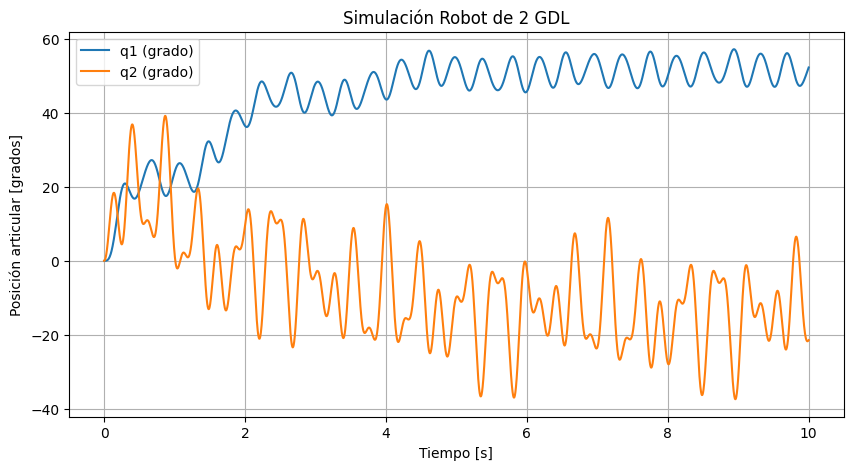

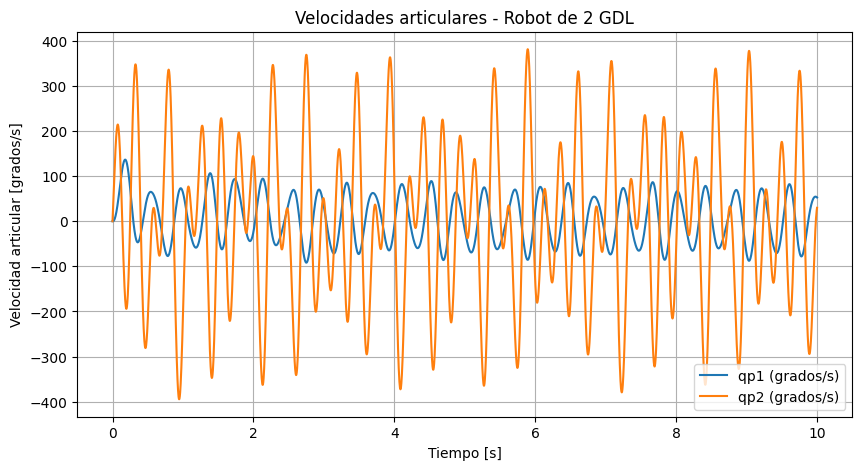

In [22]:
#PIA
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Modelo dinámico del robot de transmisión directa de 2GDL
def cap5_robot2gdl(t, x):

    q1, q2 = x[0], x[1]       # Posición articular
    qp1, qp2 = x[2], x[3]     # Velocidad articular
    qp = np.array([qp1, qp2])

    # Matriz de inercia
    M = np.array([[3.117 + 0.2 * np.cos(q2), 0.108 + 0.1 * np.cos(q2)], [0.108 + 0.1 * np.cos(q2), 0.108]])

    # Matriz de fuerzas centrípetas y de Coriolis
    C = np.array([[-0.2 * np.sin(q2) * qp2, -0.1 * np.sin(q2) * qp2], [0.1 * np.sin(q2) * qp1,  0.0]])

    # Vector de pares gravitacionales
    par_grav = np.array([39.3 * np.sin(q1) + 1.95 * np.sin(q1 + q2), 1.95 * np.sin(q1 + q2)])

    # Vector de pares de fricción viscosa y de Coulomb
    fr = np.array([1.86 * qp1 + 1.93 * np.sign(qp1), 0.16 * qp2 + 0.3 * np.sign(qp2)])

    # Vector de pares aplicados (tau)
    tau = np.array([(1 - np.exp(-0.8 * t)) * 32.0 + 56 * np.sin(16 * t + 0.1) + 12 * np.sin(20 * t + 0.15), (1 - np.exp(-1.8 * t)) * 1.2 + 8 * np.sin(26 * t + 0.8) + 2 * np.sin(12 * t + 0.34)])

    # Vector de aceleración articular: q2p = inv(M) * (tau - C*qp - par_grav - fr)
    q2p = np.linalg.solve(M, tau - C @ qp - par_grav - fr)

    # Vector de salida (derivadas de estado)
    return [qp1, qp2, q2p[0], q2p[1]]

# Parámetros de simulación
ti = 0       # Tiempo inicial
h = 0.0025   # Incremento de tiempo
tf = 10      # Tiempo final
ts = np.arange(ti, tf + h, h) # Vector de tiempo

# Condiciones iniciales [q1, q2, qp1, qp2]
x0 = [0, 0, 0, 0]

# Solución numérica (equivalente a ode45 en MATLAB)
sol = solve_ivp(cap5_robot2gdl, [ti, tf], x0, method='RK45', t_eval=ts, rtol=1e-3, first_step=2.5e-3, max_step=2.5e-3)

# Gráfica de resultados (radianes a grados)
plt.figure(figsize=(10, 5))
plt.plot(sol.t, (180 / np.pi) * sol.y[0], label='q1 (grado)')
plt.plot(sol.t, (180 / np.pi) * sol.y[1], label='q2 (grado)')
plt.title('Simulación Robot de 2 GDL')
plt.xlabel('Tiempo [s]')
plt.ylabel('Posición articular [grados]')
plt.legend()
plt.grid()
plt.show()

# Gráfica de velocidades articulares (rad/s o grados/s)
plt.figure(figsize=(10, 5))
plt.plot(sol.t, (180 / np.pi) * sol.y[2], label='qp1 (grados/s)')
plt.plot(sol.t, (180 / np.pi) * sol.y[3], label='qp2 (grados/s)')
plt.title('Velocidades articulares - Robot de 2 GDL')
plt.xlabel('Tiempo [s]')
plt.ylabel('Velocidad articular [grados/s]')
plt.legend()
plt.grid()
plt.show()
